# Notebook 03 — Exploratory Data Analysis

## Project: Predicting Obesity Among U.S. Adults Using Machine Learning

### Objective
This notebook explores the distribution of obesity and its relationships with demographic, socioeconomic, lifestyle and clinical characteristics among adults in the analytical NHANES dataset.

Obesity is defined as BMI ≥ 30 kg/m². BMI is used to define the outcome but is not treated as a predictor. Waist circumference is also excluded from predictor-focused analyses because of its close anthropometric relationship with BMI-defined obesity.

The exploratory analysis focuses on identifying patterns and associations that may inform subsequent machine-learning classification. These analyses are descriptive and are not intended to establish causal relationships.

### Step 1. Import Libraries, Load, and Inspect the Cleaned Dataset
The cleaned adult NHANES dataset produced in Notebook 02 was loaded and inspected before exploratory analysis.

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../outputs/NHANES_Cleaned_Adults.csv")

In [2]:
# Check the data size
print("Dataset shape:", df.shape)

Dataset shape: (16943, 48)


In [3]:
print("Unique participants:", df["SEQN"].nunique())
print("Missing obesity outcome:", df["Obesity"].isna().sum())

Unique participants: 16943
Missing obesity outcome: 0


In [4]:
# Look at the first few rows
df.head()

,SEQN,RIDAGEYR,RIAGENDR,RIDRETH3,DMDEDUC2,DMDMARTL,INDFMPIR,BMXBMI,BMXWAIST,BPXSY1,...,Congestive_Heart_Failure,Coronary_Heart_Disease,Heart_Attack,Stroke,Vigorous_Work_Activity,Moderate_Work_Activity,Vigorous_Recreational_Activity,Weight_Change_Intent,Depressed_Hopeless,Drug_Use
0,73557.0,69.0,1.0,4.0,3.0,4.0,0.84,26.7,100.0,122.0,...,No,No,No,Yes,No,No,No,Not trying,Not at all,Unknown
1,73558.0,54.0,1.0,3.0,3.0,1.0,1.78,28.6,107.6,156.0,...,No,No,No,No,No,Yes,No,Not trying,Not at all,Yes
2,73559.0,72.0,1.0,3.0,4.0,1.0,4.51,28.9,109.2,140.0,...,No,No,No,No,No,Yes,No,Not trying,Not at all,Unknown
3,73561.0,73.0,2.0,3.0,5.0,1.0,5.00,19.7,NaN,136.0,...,No,No,No,No,No,Yes,No,No,Several days,Unknown
4,73562.0,56.0,1.0,1.0,4.0,3.0,4.79,41.7,123.1,160.0,...,No,Yes,Yes,No,Yes,No,No,Yes,Nearly every day,Yes


In [5]:
# Look at the last few rows
df.tail()

,SEQN,RIDAGEYR,RIAGENDR,RIDRETH3,DMDEDUC2,DMDMARTL,INDFMPIR,BMXBMI,BMXWAIST,BPXSY1,...,Congestive_Heart_Failure,Coronary_Heart_Disease,Heart_Attack,Stroke,Vigorous_Work_Activity,Moderate_Work_Activity,Vigorous_Recreational_Activity,Weight_Change_Intent,Depressed_Hopeless,Drug_Use
16938,102949.0,33.0,1.0,3.0,3.0,6.0,1.01,23.7,85.5,120.0,...,No,No,No,No,Yes,Yes,No,Not trying,Not at all,Yes
16939,102952.0,70.0,2.0,6.0,3.0,1.0,0.95,20.0,82.2,136.0,...,No,No,No,No,No,No,No,Not trying,Not at all,Unknown
16940,102953.0,42.0,1.0,1.0,3.0,4.0,NaN,35.8,114.8,124.0,...,No,No,No,No,Yes,Yes,No,Yes,Several days,No
16941,102954.0,41.0,2.0,4.0,5.0,5.0,1.18,26.1,86.4,116.0,...,No,No,No,No,No,No,No,Not trying,Not at all,No
16942,102956.0,38.0,1.0,3.0,4.0,3.0,1.56,36.1,122.0,150.0,...,No,No,No,No,No,No,No,Yes,Several days,Yes


### Step 2. Examine the Obesity Outcome Distribution
The distribution of the binary obesity outcome was examined to assess the balance between the two classification classes.

Because survey weights are not applied in this project, these percentages describe the analytical sample and should not be interpreted as nationally representative U.S. obesity prevalence estimates.

In [6]:
# Summarise obesity class counts and percentages
obesity_counts = df["Obesity"].value_counts().sort_index()
obesity_percent = df["Obesity"].value_counts(normalize=True).sort_index() * 100

obesity_summary = pd.DataFrame({
    "Group": ["Not obese", "Obese"],
    "Count": obesity_counts.values,
    "Percent": obesity_percent.values.round(2)
})

obesity_summary

,Group,Count,Percent
0,Not obese,10309,60.85
1,Obese,6634,39.15


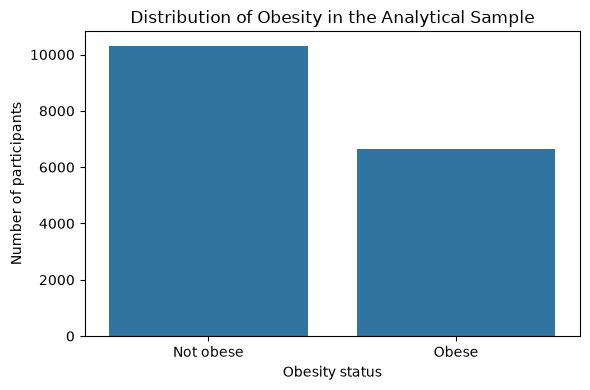

In [7]:
# Count plot of obesity status
plt.figure(figsize=(6, 4))

sns.countplot(
    data=df,
    x="Obesity"
)

plt.xticks([0, 1], ["Not obese", "Obese"])
plt.xlabel("Obesity status")
plt.ylabel("Number of participants")
plt.title("Distribution of Obesity in the Analytical Sample")

plt.tight_layout()
plt.show()

The analytical sample included 10,309 (60.85%) participants classified as not obese and 6,634 (39.15%) classified as obese. Although the classes were moderately imbalanced, both groups were sufficiently represented for classification modelling. These percentages describe the analytical sample and are not survey-weighted estimates of U.S. obesity prevalence.

### Step 3. Examine Obesity by Sex
The proportion of participants classified as obese was compared between males and females to examine whether obesity status differed by sex in the analytical sample.

In [8]:
# Summarise obesity by sex
obesity_by_sex = (
    df.groupby("Sex")["Obesity"]
      .agg(["count", "sum", "mean"])
      .reset_index()
)

obesity_by_sex["Obesity_Percent"] = (
    obesity_by_sex["mean"] * 100
).round(2)

obesity_by_sex = obesity_by_sex.rename(columns={
    "count": "Participants",
    "sum": "Obese_Count"
})

obesity_by_sex[
    ["Sex", "Participants", "Obese_Count", "Obesity_Percent"]
]

,Sex,Participants,Obese_Count,Obesity_Percent
0,Female,8811,3760,42.67
1,Male,8132,2874,35.34


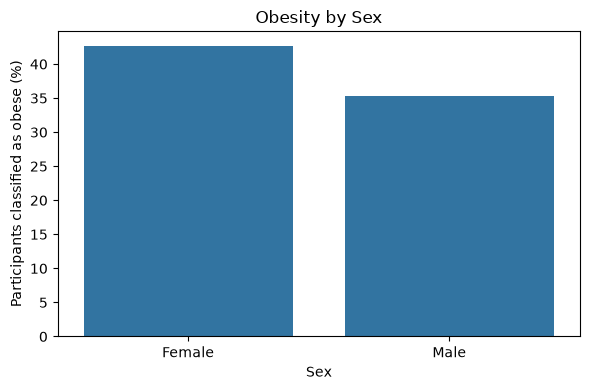

In [9]:
# Bar plot of obesity percentage by sex
sex_plot = (
    df.groupby("Sex")["Obesity"]
      .mean()
      .mul(100)
      .reset_index(name="Obesity_Percent")
)

plt.figure(figsize=(6, 4))

sns.barplot(
    data=sex_plot,
    x="Sex",
    y="Obesity_Percent"
)

plt.xlabel("Sex")
plt.ylabel("Participants classified as obese (%)")
plt.title("Obesity by Sex")

plt.tight_layout()
plt.show()

Females had a higher proportion of obesity than males in the analytical sample (42.67% vs 35.34%). This descriptive difference indicates that sex may contribute useful information to the subsequent classification models; however, the analysis does not establish a causal relationship.

### Step 4. Examine Obesity by Age
Age was grouped into categories for descriptive analysis to examine how the proportion classified as obese varied across adulthood. The original continuous age variable was retained for machine-learning modelling.

In [10]:
# Create age groups for descriptive analysis
age_bins = [18, 30, 40, 50, 60, 70, np.inf]
age_labels = [
    "18–29",
    "30–39",
    "40–49",
    "50–59",
    "60–69",
    "70+"
]

df["Age_Group"] = pd.cut(
    df["RIDAGEYR"],
    bins=age_bins,
    labels=age_labels,
    right=False
)

In [11]:
# Summarise obesity by age group
obesity_by_age = (
    df.groupby("Age_Group", observed=False)["Obesity"]
      .agg(["count", "sum", "mean"])
      .reset_index()
)

obesity_by_age["Obesity_Percent"] = (
    obesity_by_age["mean"] * 100
).round(2)

obesity_by_age = obesity_by_age.rename(columns={
    "count": "Participants",
    "sum": "Obese_Count"
})

obesity_by_age[
    ["Age_Group", "Participants", "Obese_Count", "Obesity_Percent"]
]

,Age_Group,Participants,Obese_Count,Obesity_Percent
0,18–29,3450,1056,30.61
1,30–39,2683,1106,41.22
2,40–49,2667,1151,43.16
3,50–59,2659,1157,43.51
4,60–69,2845,1229,43.20
5,70+,2639,935,35.43


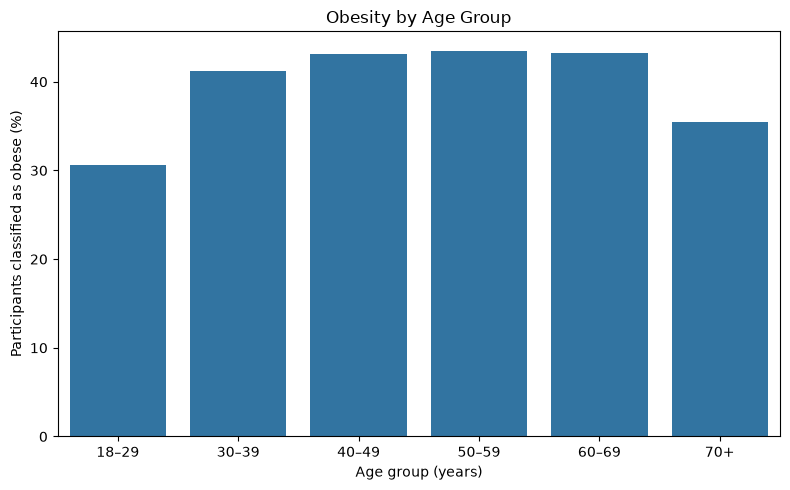

In [12]:
# Bar plot of obesity percentage by age group
plt.figure(figsize=(8, 5))

sns.barplot(
    data=obesity_by_age,
    x="Age_Group",
    y="Obesity_Percent"
)

plt.xlabel("Age group (years)")
plt.ylabel("Participants classified as obese (%)")
plt.title("Obesity by Age Group")

plt.tight_layout()
plt.show()

The proportion classified as obese varied across age groups. It was lowest among participants aged 18–29 years (30.61%), increased through middle adulthood, and remained around 43% among participants aged 40–69 years before decreasing to 35.43% among those aged 70 years and older. This pattern suggests that the relationship between age and obesity in the analytical sample is not simply linear.

### Step 5. Examine Obesity by Race/Ethnicity
Obesity proportions were compared across the NHANES race/ethnicity categories to examine variation in the outcome across demographic groups.

In [13]:
# Summarise obesity by race/ethnicity
obesity_by_race = (
    df.groupby("Race_Ethnicity")["Obesity"]
      .agg(["count", "sum", "mean"])
      .reset_index()
)

obesity_by_race["Obesity_Percent"] = (
    obesity_by_race["mean"] * 100
).round(2)

obesity_by_race = obesity_by_race.rename(columns={
    "count": "Participants",
    "sum": "Obese_Count"
})

obesity_by_race[
    ["Race_Ethnicity", "Participants",
     "Obese_Count", "Obesity_Percent"]
].sort_values("Obesity_Percent", ascending=False)

,Race_Ethnicity,Participants,Obese_Count,Obesity_Percent
0,Mexican American,2553,1210,47.40
2,Non-Hispanic Black,3675,1723,46.88
5,Other/Multi-Racial,676,305,45.12
4,Other Hispanic,1770,709,40.06
3,Non-Hispanic White,6138,2399,39.08
1,Non-Hispanic Asian,2131,288,13.51


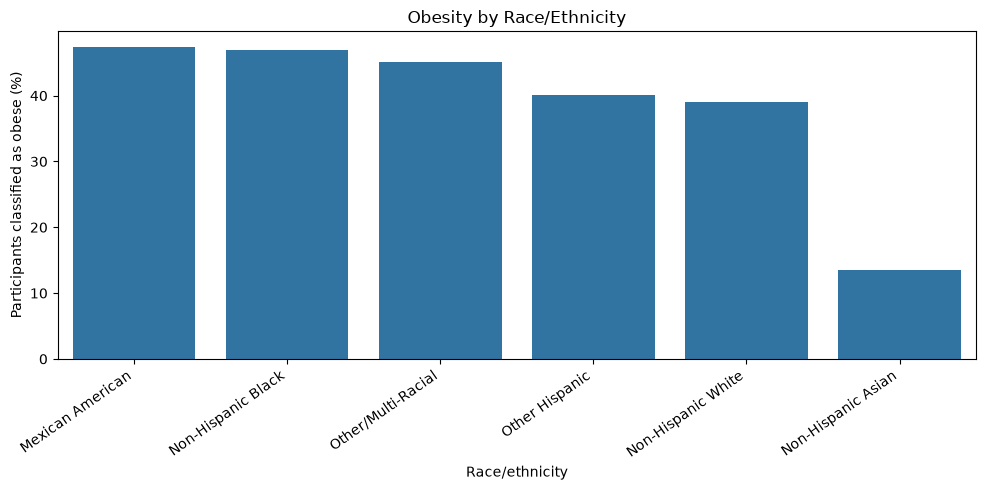

In [14]:
# Bar plot of obesity percentage by race/ethnicity
race_plot = obesity_by_race.sort_values(
    "Obesity_Percent",
    ascending=False
)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=race_plot,
    x="Race_Ethnicity",
    y="Obesity_Percent"
)

plt.xlabel("Race/ethnicity")
plt.ylabel("Participants classified as obese (%)")
plt.title("Obesity by Race/Ethnicity")
plt.xticks(rotation=35, ha="right")

plt.tight_layout()
plt.show()

The proportion classified as obese varied across race/ethnicity groups. Mexican American (47.40%) and non-Hispanic Black (46.88%) participants had the highest proportions, followed by Other/Multi-Racial participants (45.12%). Non-Hispanic Asian participants had the lowest proportion (13.51%). These descriptive differences indicate substantial variation in obesity status across race/ethnicity groups in the analytical sample.

### Step 6. Examine Obesity by Socioeconomic Characteristics
Obesity proportions were compared across education and marital-status categories to examine variation in the outcome across socioeconomic characteristics.

In [15]:
# Summarise obesity by education
obesity_by_education = (
    df.groupby("Education")["Obesity"]
      .agg(["count", "sum", "mean"])
      .reset_index()
)

obesity_by_education["Obesity_Percent"] = (
    obesity_by_education["mean"] * 100
).round(2)

obesity_by_education = obesity_by_education.rename(columns={
    "count": "Participants",
    "sum": "Obese_Count"
})

obesity_by_education[
    ["Education", "Participants", "Obese_Count", "Obesity_Percent"]
].sort_values("Obesity_Percent", ascending=False)

,Education,Participants,Obese_Count,Obesity_Percent
4,Some college/AA degree,4974,2254,45.32
2,High school/GED,3635,1544,42.48
3,Less than 9th grade,1515,616,40.66
0,9-11th grade,1974,802,40.63
1,College graduate or above,3986,1218,30.56


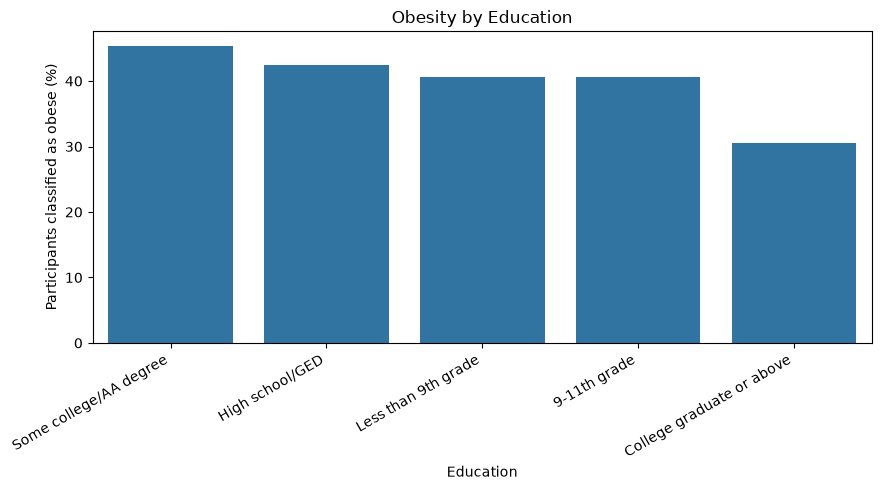

In [16]:
# Bar plot of obesity percentage by education
education_plot = obesity_by_education.sort_values(
    "Obesity_Percent",
    ascending=False
)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=education_plot,
    x="Education",
    y="Obesity_Percent"
)

plt.xlabel("Education")
plt.ylabel("Participants classified as obese (%)")
plt.title("Obesity by Education")
plt.xticks(rotation=30, ha="right")

plt.tight_layout()
plt.show()

In [17]:
# Summarise obesity by marital status
obesity_by_marital = (
    df.groupby("Marital_Status")["Obesity"]
      .agg(["count", "sum", "mean"])
      .reset_index()
)

obesity_by_marital["Obesity_Percent"] = (
    obesity_by_marital["mean"] * 100
).round(2)

obesity_by_marital = obesity_by_marital.rename(columns={
    "count": "Participants",
    "sum": "Obese_Count"
})

obesity_by_marital[
    ["Marital_Status", "Participants", "Obese_Count", "Obesity_Percent"]
].sort_values("Obesity_Percent", ascending=False)

,Marital_Status,Participants,Obese_Count,Obesity_Percent
0,Divorced,1783,795,44.59
4,Separated,543,241,44.38
5,Widowed,1194,486,40.70
1,Living with partner,1395,565,40.50
2,Married,8207,3225,39.30
3,Never married,2971,1125,37.87


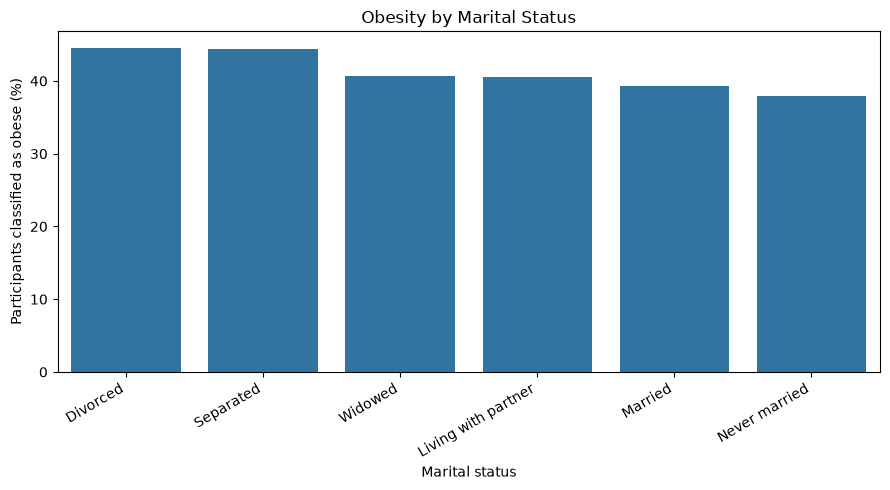

In [18]:
# Bar plot of obesity percentage by marital status
marital_plot = obesity_by_marital.sort_values(
    "Obesity_Percent",
    ascending=False
)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=marital_plot,
    x="Marital_Status",
    y="Obesity_Percent"
)

plt.xlabel("Marital status")
plt.ylabel("Participants classified as obese (%)")
plt.title("Obesity by Marital Status")
plt.xticks(rotation=30, ha="right")

plt.tight_layout()
plt.show()

Obesity proportions varied across education and marital-status categories. Participants with some college/AA education had the highest obesity proportion (45.32%), while college graduates had the lowest (30.56%). Across marital-status categories, the proportions ranged from 37.87% among never-married participants to 44.59% among divorced participants. The variation across marital-status groups was smaller than that observed across education categories.

### Step 7. Examine Obesity by Income-to-Poverty Ratio
The income-to-poverty ratio was grouped into categories for descriptive analysis to examine how the proportion classified as obese varied across income levels. The original continuous variable was retained for machine-learning modelling.

In [19]:
# Create income-to-poverty ratio groups for descriptive analysis
income_bins = [0, 1, 2, 3, 4, np.inf]
income_labels = [
    "<1",
    "1–<2",
    "2–<3",
    "3–<4",
    "≥4"
]

df["Income_Group"] = pd.cut(
    df["INDFMPIR"],
    bins=income_bins,
    labels=income_labels,
    right=False
)

In [20]:
# Summarise obesity by income-to-poverty ratio group
obesity_by_income = (
    df.groupby("Income_Group", observed=False)["Obesity"]
      .agg(["count", "sum", "mean"])
      .reset_index()
)

obesity_by_income["Obesity_Percent"] = (
    obesity_by_income["mean"] * 100
).round(2)

obesity_by_income = obesity_by_income.rename(columns={
    "count": "Participants",
    "sum": "Obese_Count"
})

obesity_by_income[
    ["Income_Group", "Participants", "Obese_Count", "Obesity_Percent"]
]

,Income_Group,Participants,Obese_Count,Obesity_Percent
0,<1,3197,1325,41.45
1,1–<2,4102,1686,41.10
2,2–<3,2356,974,41.34
3,3–<4,1660,643,38.73
4,≥4,3712,1288,34.70


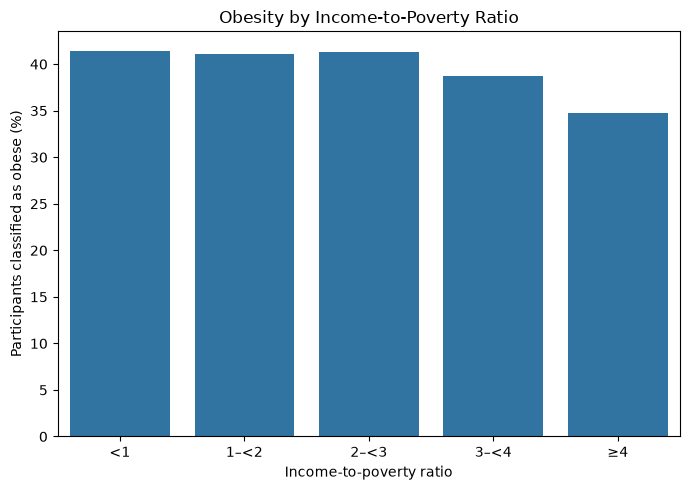

In [21]:
# Bar plot of obesity percentage by income-to-poverty ratio group
plt.figure(figsize=(7, 5))

sns.barplot(
    data=obesity_by_income,
    x="Income_Group",
    y="Obesity_Percent"
)

plt.xlabel("Income-to-poverty ratio")
plt.ylabel("Participants classified as obese (%)")
plt.title("Obesity by Income-to-Poverty Ratio")

plt.tight_layout()
plt.show()

The proportion classified as obese was similar among participants with income-to-poverty ratios below 3 (41.10–41.45%). The proportion decreased to 38.73% among participants with ratios of 3–<4 and to 34.70% among those with ratios ≥4. This pattern suggests lower obesity proportions at higher income-to-poverty ratios in the analytical sample.

### Step 8. Examine Obesity by Lifestyle Characteristics
Obesity proportions were compared across smoking and physical-activity characteristics to examine variation in the outcome across lifestyle factors.

In [22]:
# Summarise obesity by smoking and physical-activity characteristics
lifestyle_vars = {
    "Smoked_100_Cigarettes": "Smoked ≥100 cigarettes",
    "Vigorous_Work_Activity": "Vigorous work activity",
    "Moderate_Work_Activity": "Moderate work activity",
    "Vigorous_Recreational_Activity": "Vigorous recreational activity"
}

lifestyle_results = {}

for variable, label in lifestyle_vars.items():
    summary = (
        df.groupby(variable)["Obesity"]
          .agg(["count", "sum", "mean"])
          .reset_index()
    )

    summary["Obesity_Percent"] = (summary["mean"] * 100).round(2)

    summary = summary.rename(columns={
        variable: "Category",
        "count": "Participants",
        "sum": "Obese_Count"
    })

    lifestyle_results[label] = summary[
        ["Category", "Participants", "Obese_Count", "Obesity_Percent"]
    ]

for label, table in lifestyle_results.items():
    print(f"\n{label}")
    display(table)


Smoked ≥100 cigarettes


,Category,Participants,Obese_Count,Obesity_Percent
0,No,10001,3829,38.29
1,Yes,6931,2801,40.41



Vigorous work activity


,Category,Participants,Obese_Count,Obesity_Percent
0,No,13376,5135,38.39
1,Yes,3558,1497,42.07



Moderate work activity


,Category,Participants,Obese_Count,Obesity_Percent
0,No,10536,3958,37.57
1,Yes,6395,2672,41.78



Vigorous recreational activity


,Category,Participants,Obese_Count,Obesity_Percent
0,No,12775,5412,42.36
1,Yes,4167,1222,29.33


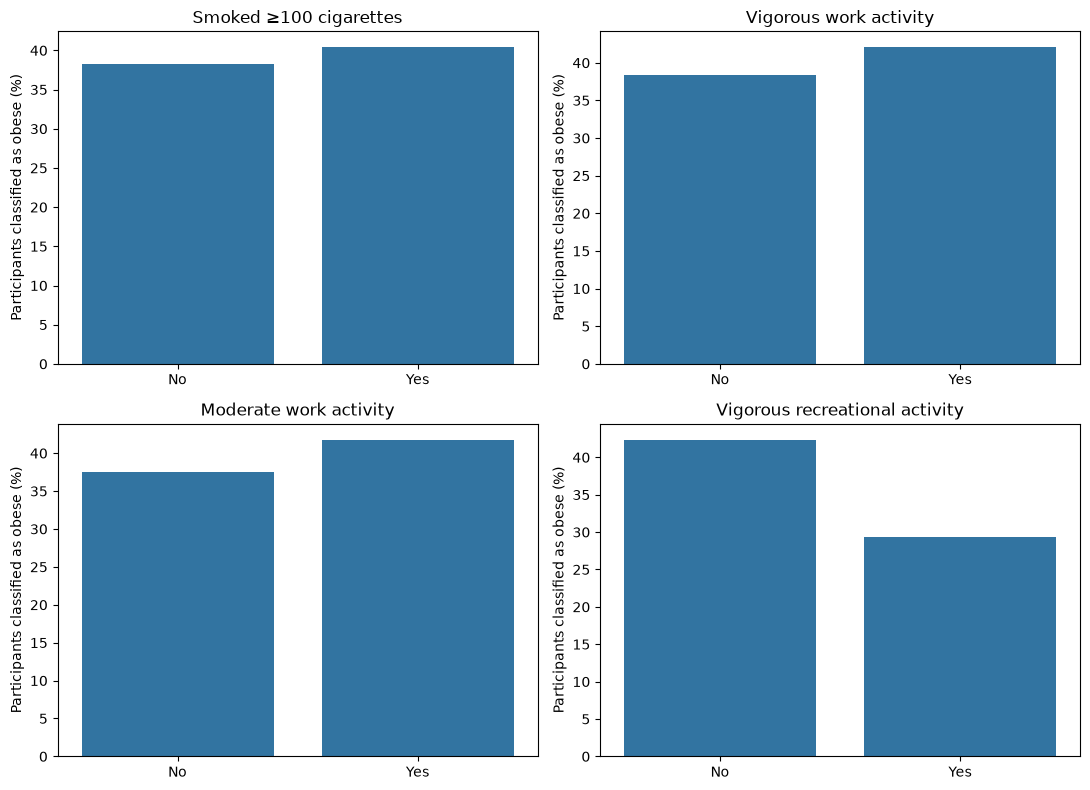

In [23]:
# Bar plots of obesity percentage by lifestyle characteristics
fig, axes = plt.subplots(2, 2, figsize=(11, 8))

for ax, (variable, title) in zip(axes.flatten(), lifestyle_vars.items()):

    plot_data = (
        df.groupby(variable)["Obesity"]
          .mean()
          .mul(100)
          .reset_index(name="Obesity_Percent")
    )

    sns.barplot(
        data=plot_data,
        x=variable,
        y="Obesity_Percent",
        ax=ax
    )

    ax.set_title(title)
    ax.set_xlabel("")
    ax.set_ylabel("Participants classified as obese (%)")

plt.tight_layout()
plt.show()

Smoking history showed only a small difference in obesity proportions (40.41% among participants who had smoked ≥100 cigarettes vs 38.29% among those who had not). Obesity proportions were higher among participants reporting vigorous (42.07%) or moderate (41.78%) work activity than among those reporting no such work activity. In contrast, participants reporting vigorous recreational activity had a substantially lower obesity proportion than those who did not (29.33% vs 42.36%). These findings describe unadjusted associations and do not establish causal relationships.

### Step 9. Examine Obesity by Weight-Change Intention
Obesity proportions were compared across weight-change intention categories to examine variation in obesity status according to participants' reported weight-management intentions.

In [24]:
# Summarise obesity by weight-change intention
obesity_by_weight_intent = (
    df.groupby("Weight_Change_Intent")["Obesity"]
      .agg(["count", "sum", "mean"])
      .reset_index()
)

obesity_by_weight_intent["Obesity_Percent"] = (
    obesity_by_weight_intent["mean"] * 100
).round(2)

obesity_by_weight_intent = obesity_by_weight_intent.rename(columns={
    "count": "Participants",
    "sum": "Obese_Count"
})

obesity_by_weight_intent[
    ["Weight_Change_Intent", "Participants",
     "Obese_Count", "Obesity_Percent"]
].sort_values("Obesity_Percent", ascending=False)

,Weight_Change_Intent,Participants,Obese_Count,Obesity_Percent
2,Yes,8640,5664,65.56
1,Not trying,7284,911,12.51
0,No,979,45,4.60


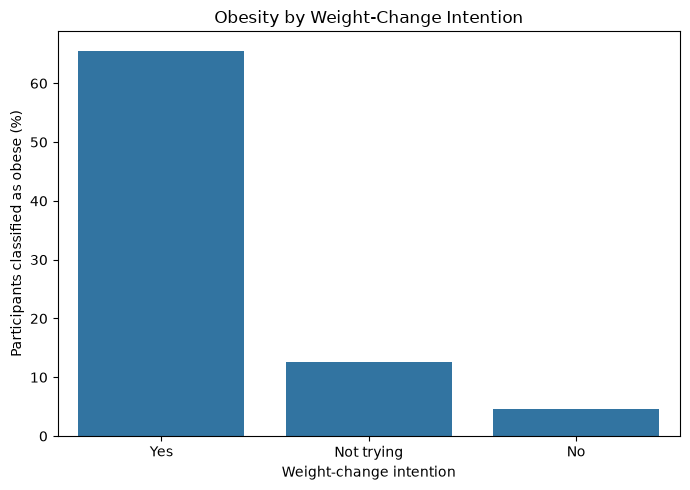

In [25]:
# Bar plot of obesity percentage by weight-change intention
weight_intent_plot = obesity_by_weight_intent.sort_values(
    "Obesity_Percent",
    ascending=False
)

plt.figure(figsize=(7, 5))

sns.barplot(
    data=weight_intent_plot,
    x="Weight_Change_Intent",
    y="Obesity_Percent"
)

plt.xlabel("Weight-change intention")
plt.ylabel("Participants classified as obese (%)")
plt.title("Obesity by Weight-Change Intention")

plt.tight_layout()
plt.show()

The proportion classified as obese varied substantially by weight-change intention. Obesity was present among 65.56% of participants reporting an intention to change weight, compared with 12.51% of those not trying and 4.60% of those reporting no intention. This strong association should be interpreted cautiously because weight-change intention may reflect participants' existing body weight or weight concerns rather than being an independent antecedent of obesity.

### Step 10. Examine Obesity by Clinical Characteristics
Obesity proportions were compared across diabetes, prediabetes and cardiovascular-condition categories to examine variation in the outcome across clinical characteristics.

#### Step 10.1. Examine Obesity by Diabetes/Prediabetes Status
Diabetes and prediabetes information was combined into mutually exclusive categories to compare obesity proportions among participants with diabetes, prediabetes, and neither condition.

In [26]:
# Create mutually exclusive diabetes/prediabetes status
def classify_glycaemic_status(row):
    if row["Diabetes"] == "Yes":
        return "Diabetes"
    elif row["Prediabetes"] == "Yes" or row["Diabetes"] == "Borderline":
        return "Prediabetes"
    elif row["Diabetes"] == "No" and row["Prediabetes"] == "No":
        return "Neither"
    else:
        return np.nan

df["Diabetes_Status"] = df.apply(
    classify_glycaemic_status,
    axis=1
)


# Check diabetes/prediabetes status categories
df["Diabetes_Status"].value_counts(dropna=False)

Diabetes_Status
Neither        12869
Diabetes        2303
Prediabetes     1746
NaN               25
Name: count, dtype: int64

In [27]:
# Summarise obesity by diabetes/prediabetes status
obesity_by_diabetes_status = (
    df.groupby("Diabetes_Status")["Obesity"]
      .agg(["count", "sum", "mean"])
      .reset_index()
)

obesity_by_diabetes_status["Obesity_Percent"] = (
    obesity_by_diabetes_status["mean"] * 100
).round(2)

obesity_by_diabetes_status = obesity_by_diabetes_status.rename(columns={
    "count": "Participants",
    "sum": "Obese_Count"
})

obesity_by_diabetes_status[
    ["Diabetes_Status", "Participants",
     "Obese_Count", "Obesity_Percent"]
]

,Diabetes_Status,Participants,Obese_Count,Obesity_Percent
0,Diabetes,2303,1305,56.67
1,Neither,12869,4402,34.21
2,Prediabetes,1746,913,52.29


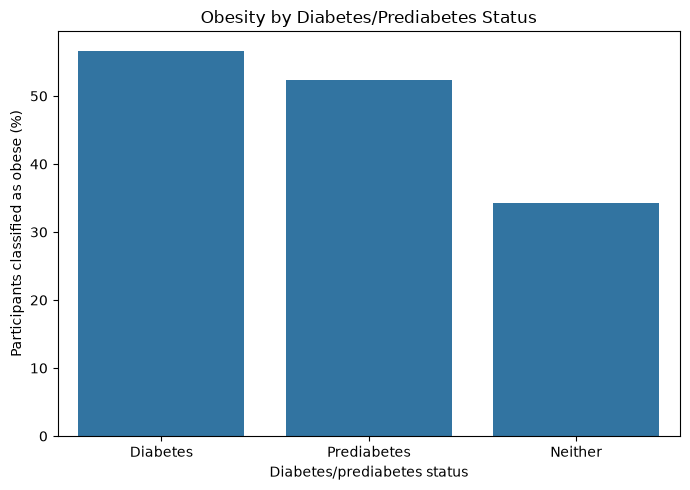

In [28]:
# Bar plot of obesity percentage by diabetes/prediabetes status
status_order = ["Diabetes", "Prediabetes", "Neither"]

plt.figure(figsize=(7, 5))

sns.barplot(
    data=obesity_by_diabetes_status,
    x="Diabetes_Status",
    y="Obesity_Percent",
    order=status_order
)

plt.xlabel("Diabetes/prediabetes status")
plt.ylabel("Participants classified as obese (%)")
plt.title("Obesity by Diabetes/Prediabetes Status")

plt.tight_layout()
plt.show()

Participants with diabetes had the highest obesity proportion (56.67%), followed by those with prediabetes (52.29%). In comparison, 34.21% of participants with neither diabetes nor prediabetes were classified as obese. Twenty-five participants could not be assigned to one of these categories because of missing information.

#### Step 10.2. Examine Obesity by Cardiovascular Conditions
Obesity proportions were compared among participants reporting selected cardiovascular conditions to examine variation in the outcome across cardiovascular health characteristics.

In [29]:
# Combine cardiovascular conditions into one summary table
cardiovascular_vars = {
    "Congestive_Heart_Failure": "Congestive heart failure",
    "Coronary_Heart_Disease": "Coronary heart disease",
    "Heart_Attack": "Heart attack",
    "Stroke": "Stroke"
}

cardiovascular_summary = []

for variable, label in cardiovascular_vars.items():
    subset = df[df[variable] == "Yes"]

    cardiovascular_summary.append({
        "Condition": label,
        "Participants": len(subset),
        "Obese_Count": subset["Obesity"].sum(),
        "Obesity_Percent": round(subset["Obesity"].mean() * 100, 2)
    })

cardiovascular_summary = pd.DataFrame(cardiovascular_summary)

cardiovascular_summary

,Condition,Participants,Obese_Count,Obesity_Percent
0,Congestive heart failure,537,310,57.73
1,Coronary heart disease,670,301,44.93
2,Heart attack,694,316,45.53
3,Stroke,613,270,44.05


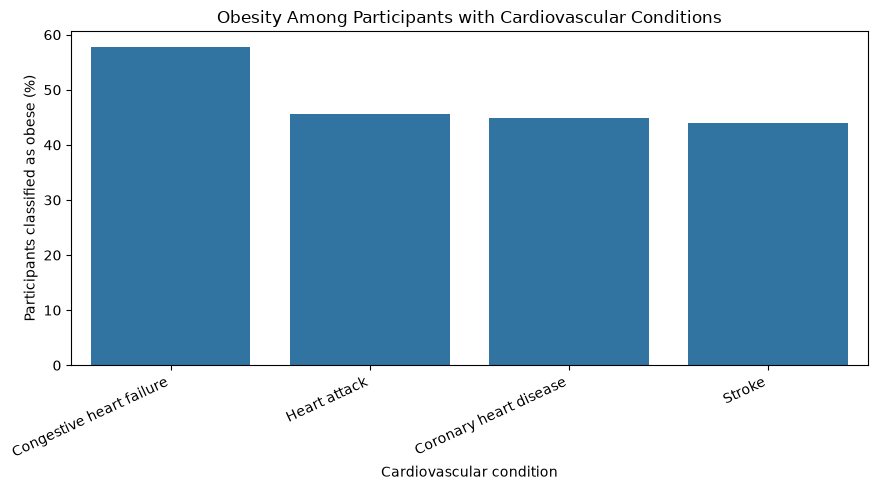

In [30]:
# Bar plot of obesity percentage by cardiovascular condition
cardiovascular_plot = cardiovascular_summary.sort_values(
    "Obesity_Percent",
    ascending=False
)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=cardiovascular_plot,
    x="Condition",
    y="Obesity_Percent"
)

plt.xlabel("Cardiovascular condition")
plt.ylabel("Participants classified as obese (%)")
plt.title("Obesity Among Participants with Cardiovascular Conditions")
plt.xticks(rotation=25, ha="right")

plt.tight_layout()
plt.show()

Among participants reporting cardiovascular conditions, those with congestive heart failure had the highest obesity proportion (57.73%). Obesity proportions were similar among participants reporting heart attack (45.53%), coronary heart disease (44.93%), and stroke (44.05%). Because these conditions are not mutually exclusive, participants may contribute to more than one condition category.

#### Step 10.3. Examine Obesity by Arthritis Status
Obesity proportions were compared between participants with and without reported arthritis to examine variation in the outcome according to arthritis status.

In [31]:
# Summarise obesity by arthritis status
obesity_by_arthritis = (
    df.groupby("Arthritis")["Obesity"]
      .agg(["count", "sum", "mean"])
      .reset_index()
)

obesity_by_arthritis["Obesity_Percent"] = (
    obesity_by_arthritis["mean"] * 100
).round(2)

obesity_by_arthritis = obesity_by_arthritis.rename(columns={
    "count": "Participants",
    "sum": "Obese_Count"
})

obesity_by_arthritis[
    ["Arthritis", "Participants",
     "Obese_Count", "Obesity_Percent"]
]

,Arthritis,Participants,Obese_Count,Obesity_Percent
0,No,11666,4162,35.68
1,Yes,4400,2262,51.41


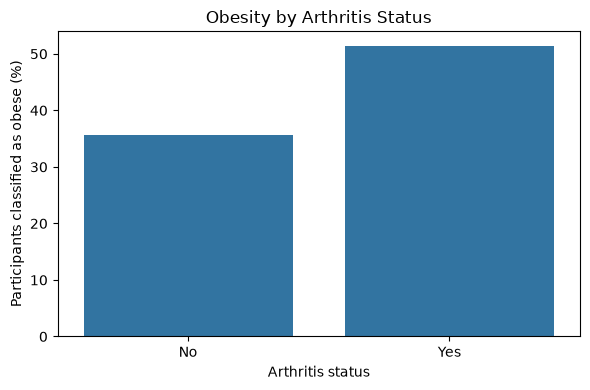

In [32]:
# Bar plot of obesity percentage by arthritis status
plt.figure(figsize=(6, 4))

sns.barplot(
    data=obesity_by_arthritis,
    x="Arthritis",
    y="Obesity_Percent"
)

plt.xlabel("Arthritis status")
plt.ylabel("Participants classified as obese (%)")
plt.title("Obesity by Arthritis Status")

plt.tight_layout()
plt.show()

Participants reporting arthritis had a higher obesity proportion than those without arthritis (51.41% vs 35.68%). This represents an unadjusted association and does not establish the direction or cause of the relationship.

### Step 11. Examine Continuous Clinical Characteristics
Continuous clinical measurements were compared between participants classified as obese and not obese to examine differences in their distributions according to obesity status.

The table summarises clinical measurements among participants classified as obese, while the accompanying boxplots compare the distributions between obese and non-obese participants. Obesity percentages were calculated among participants with available measurements for each variable.

In [33]:
# Summarise continuous clinical measurements among obese participants
clinical_continuous = {
    "BPXSY1": "Systolic blood pressure",
    "BPXDI1": "Diastolic blood pressure",
    "LBDHDD": "HDL cholesterol",
    "LBXTC": "Total cholesterol",
    "LBXGH": "HbA1c"
}

clinical_summary = []

for variable, label in clinical_continuous.items():

    available = df[df[variable].notna()]
    obese = available[available["Obesity"] == 1][variable]

    clinical_summary.append({
        "Variable": label,
        "Obese_N": obese.notna().sum(),
        "Mean": round(obese.mean(), 2),
        "Median": round(obese.median(), 2),
        "Obese (%)": round(
            (available["Obesity"] == 1).mean() * 100, 2
        )
    })

clinical_summary = pd.DataFrame(clinical_summary)

clinical_summary

,Variable,Obese_N,Mean,Median,Obese (%)
0,Systolic blood pressure,6012,126.66,124.0,38.67
1,Diastolic blood pressure,5981,72.03,72.0,38.70
2,HDL cholesterol,6299,48.66,47.0,39.37
3,Total cholesterol,6299,189.43,186.0,39.37
4,HbA1c,6369,6.03,5.7,39.37


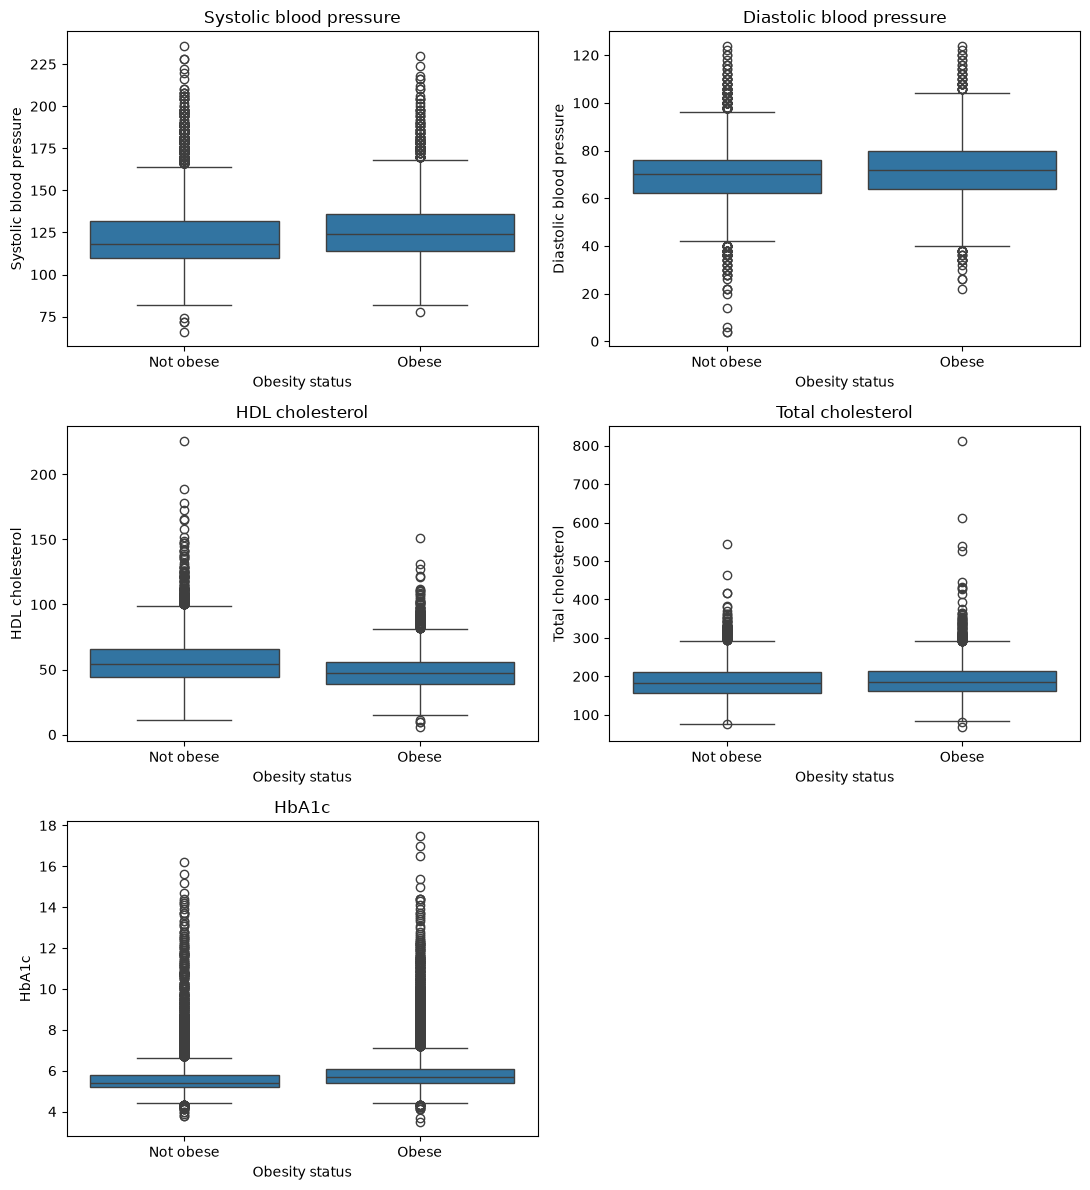

In [34]:
# Boxplots of continuous clinical measurements by obesity status
fig, axes = plt.subplots(3, 2, figsize=(11, 12))
axes = axes.flatten()

for ax, (variable, title) in zip(
    axes,
    clinical_continuous.items()
):

    sns.boxplot(
        data=df,
        x="Obesity",
        y=variable,
        ax=ax
    )

    ax.set_xticks([0, 1])
    ax.set_xticklabels(["Not obese", "Obese"])
    ax.set_xlabel("Obesity status")
    ax.set_ylabel(title)
    ax.set_title(title)

# Remove unused panel
fig.delaxes(axes[-1])

plt.tight_layout()
plt.show()

Participants classified as obese had higher systolic and diastolic blood pressure and HbA1c, and lower HDL cholesterol, than participants classified as not obese. Total cholesterol distributions were broadly similar between the groups. Among participants with available measurements, approximately 39% were classified as obese across the clinical variables examined.

### Step 12. Examine Additional Lifestyle and Psychosocial Characteristics

Sedentary time, depressive symptoms and drug-use history were examined to assess variation in obesity status across additional lifestyle and psychosocial characteristics.

#### Step 12.1. Summarise sedentary time among participants classified as obese

In [35]:
# 12.1 Summarise sedentary time among participants classified as obese
available_sedentary = df[df["PAD680"].notna()]
obese_sedentary = available_sedentary[
    available_sedentary["Obesity"] == 1
]["PAD680"]

sedentary_summary = pd.DataFrame({
    "Variable": ["Sedentary time"],
    "Obese_N": [obese_sedentary.notna().sum()],
    "Mean": [round(obese_sedentary.mean(), 2)],
    "Median": [round(obese_sedentary.median(), 2)],
    "Obese (%)": [
        round(
            (available_sedentary["Obesity"] == 1).mean() * 100,
            2
        )
    ]
})

sedentary_summary

,Variable,Obese_N,Mean,Median,Obese (%)
0,Sedentary time,6577,391.42,360.0,39.11


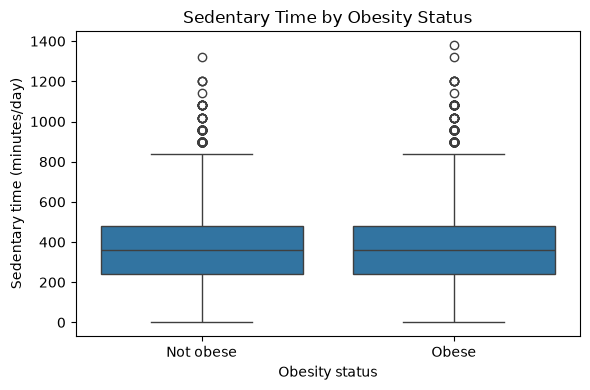

In [36]:
# Boxplot of sedentary time by obesity status
plt.figure(figsize=(6, 4))

sns.boxplot(
    data=df,
    x="Obesity",
    y="PAD680"
)

plt.xticks([0, 1], ["Not obese", "Obese"])
plt.xlabel("Obesity status")
plt.ylabel("Sedentary time (minutes/day)")
plt.title("Sedentary Time by Obesity Status")

plt.tight_layout()
plt.show()

Sedentary-time distributions were broadly similar between participants classified as obese and not obese, with substantial variability within both groups.

#### Step 12.2. Summarise obesity by depressive symptoms

In [37]:
# 12.2 Summarise obesity by depressive symptoms
depression_summary = (
    df.dropna(subset=["Depressed_Hopeless"])
      .groupby("Depressed_Hopeless", observed=True)
      .agg(
          Participants=("Obesity", "size"),
          Obese_N=("Obesity", "sum"),
          Obese_Percent=("Obesity", lambda x: x.mean() * 100)
      )
      .reset_index()
)

# Arrange categories in their natural order
depression_order = [
    "Not at all",
    "Several days",
    "More than half the days",
    "Nearly every day"
]

depression_summary["Depressed_Hopeless"] = pd.Categorical(
    depression_summary["Depressed_Hopeless"],
    categories=depression_order,
    ordered=True
)

depression_summary = depression_summary.sort_values(
    "Depressed_Hopeless"
)

depression_summary["Obese_Percent"] = (
    depression_summary["Obese_Percent"].round(2)
)

depression_summary

,Depressed_Hopeless,Participants,Obese_N,Obese_Percent
2,Not at all,11736,4480,38.17
3,Several days,2581,1108,42.93
0,More than half the days,637,293,46.00
1,Nearly every day,518,256,49.42


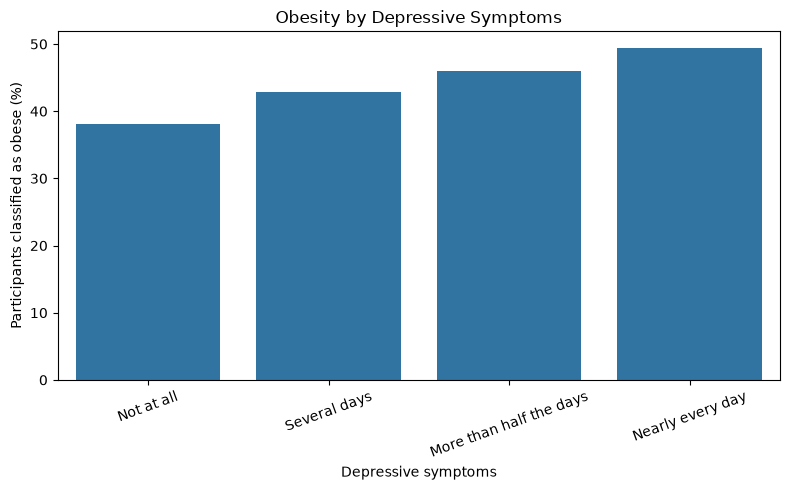

In [38]:
# Bar plot of obesity percentage by depressive symptoms
plt.figure(figsize=(8, 5))

sns.barplot(
    data=depression_summary,
    x="Depressed_Hopeless",
    y="Obese_Percent"
)

plt.xlabel("Depressive symptoms")
plt.ylabel("Participants classified as obese (%)")
plt.title("Obesity by Depressive Symptoms")
plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

The proportion classified as obese increased across the depressive-symptom categories, from 38.17% among participants reporting feeling down, depressed or hopeless "not at all" to 49.42% among those reporting these symptoms "nearly every day". This descriptive pattern indicates an association within the analytical sample but does not establish causality.

#### Step 12.3. Examine Obesity by Drug-Use History
Obesity proportions were compared according to drug-use history to examine variation in the outcome across response categories. Participants with missing drug-use information were retained as an "Unknown" category for descriptive analysis.

In [39]:
# 12.3 Summarise obesity by drug-use history
drug_summary = (
    df.groupby("Drug_Use")
      .agg(
          Participants=("Obesity", "size"),
          Obese_N=("Obesity", "sum"),
          Obese_Percent=("Obesity", lambda x: x.mean() * 100)
      )
      .reset_index()
)

drug_order = ["No", "Yes", "Unknown"]    # Unknown category = participants with missing drug-use information 

drug_summary["Drug_Use"] = pd.Categorical(
    drug_summary["Drug_Use"],
    categories=drug_order,
    ordered=True
)

drug_summary = drug_summary.sort_values("Drug_Use")
drug_summary["Obese_Percent"] = drug_summary["Obese_Percent"].round(2)

drug_summary

,Drug_Use,Participants,Obese_N,Obese_Percent
0,No,4826,1880,38.96
2,Yes,5404,2160,39.97
1,Unknown,6713,2594,38.64


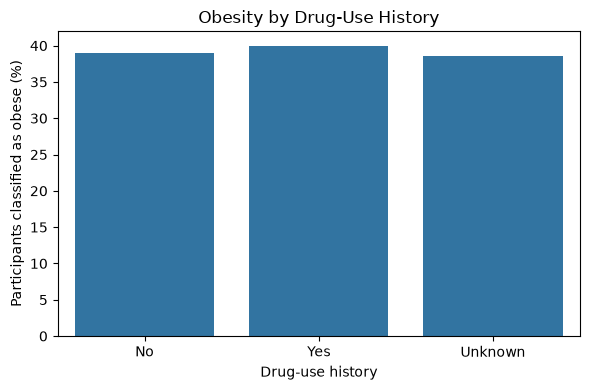

In [40]:
# Bar plot of obesity percentage by drug-use history
plt.figure(figsize=(6, 4))

sns.barplot(
    data=drug_summary,
    x="Drug_Use",
    y="Obese_Percent"
)

plt.xlabel("Drug-use history")
plt.ylabel("Participants classified as obese (%)")
plt.title("Obesity by Drug-Use History")

plt.tight_layout()
plt.show()

Obesity proportions were similar across drug-use history categories: 39.97% among participants reporting drug use, 38.96% among those reporting no drug use, and 38.64% among participants with unknown drug-use status. No substantial descriptive difference in obesity was apparent across these categories.

### Step 13. Examine Correlations Among Continuous Variables
Correlation analysis was used to examine linear relationships among continuous demographic, socioeconomic, lifestyle and clinical variables. BMI and waist circumference were excluded because they are not used as predictors in the obesity classification models.

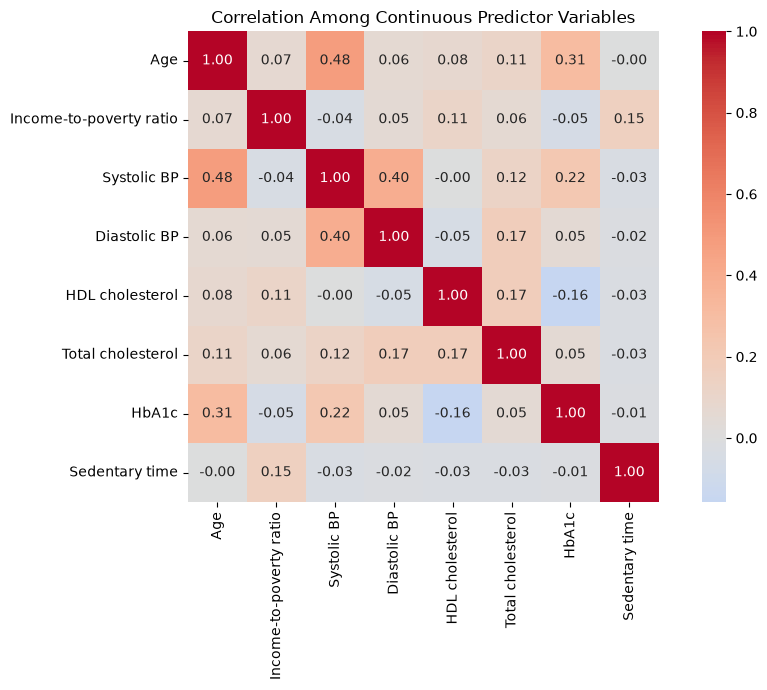

In [41]:
# Select continuous variables used as predictors
corr_vars = [
    "RIDAGEYR",
    "INDFMPIR",
    "BPXSY1",
    "BPXDI1",
    "LBDHDD",
    "LBXTC",
    "LBXGH",
    "PAD680"
]

corr_labels = {
    "RIDAGEYR": "Age",
    "INDFMPIR": "Income-to-poverty ratio",
    "BPXSY1": "Systolic BP",
    "BPXDI1": "Diastolic BP",
    "LBDHDD": "HDL cholesterol",
    "LBXTC": "Total cholesterol",
    "LBXGH": "HbA1c",
    "PAD680": "Sedentary time"
}

corr_matrix = (
    df[corr_vars]
    .rename(columns=corr_labels)
    .corr()
)

plt.figure(figsize=(10, 7))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True
)

plt.title("Correlation Among Continuous Predictor Variables")
plt.tight_layout()
plt.show()

Most continuous predictors showed weak correlations with one another. Moderate positive correlations were observed between age and systolic blood pressure (r = 0.48) and between systolic and diastolic blood pressure (r = 0.40). Age was also positively correlated with HbA1c (r = 0.31). Overall, the correlation matrix did not indicate strong linear redundancy among the continuous predictors.

### Final Predictor Check
Participant ID, BMI, waist circumference and the obesity outcome are excluded from the predictor set used for classification modelling.

In [42]:
# Confirm predictors available for obesity classification
excluded_from_modelling = [
    "SEQN",       # Participant identifier
    "BMXBMI",     # Defines the obesity outcome
    "BMXWAIST",   # Closely related anthropometric measure
    "Obesity"     # Classification target
]

print("Variables excluded from predictors:")
for variable in excluded_from_modelling:
    print("-", variable)

Variables excluded from predictors:
- SEQN
- BMXBMI
- BMXWAIST
- Obesity


## Summary of Exploratory Findings
Overall, 39.15% of participants in the analytical sample were classified as obese.

- Demographics & Socioeconomics: Obesity proportions varied across sex, age, race/ethnicity, education, and income-to-poverty ratio categories.
- Comorbidities: Higher obesity proportions were observed among participants reporting diabetes or prediabetes, arthritis, and selected cardiovascular conditions.
- Lifestyle Factors: Participants reporting vigorous recreational activity had a lower obesity proportion, while sedentary-time distributions were similar between obese and non-obese participants.
- Weight-Change Intention: Particularly large differences in obesity proportions were observed across weight-change intention categories.
- Mental Health: Obesity proportions increased progressively across depressive-symptom categories.
- Drug-Use History: Obesity proportions were similar across drug-use history categories.
- Clinical Characteristics: Participants classified as obese generally had higher blood pressure and HbA1c and lower HDL cholesterol, while total cholesterol showed comparatively little difference between groups.
- Correlations: Most continuous predictors showed weak-to-moderate correlations, with no strong linear redundancy apparent among the continuous predictors.
- Methodological Caution: These findings are descriptive and unadjusted and do not imply causal relationships.
  
The subsequent machine-learning analysis evaluates the combined predictive information provided by these characteristics.